# F1TENTH: noiseless history-projection trials

Test **$T_{\mathrm{ini}}=8$, $T_f=10$, $K=12$, $d=40$, seed 542**, with zero
measurement noise both offline and online. This is a separate exploratory run;
the retained paper results and default horizons are unchanged.

Rebuild the windows, speed-based K-means clusters, and uncentered SVD bases from
the existing clean offline trajectories. The trajectory matrix is $108\times2640$;
the selection vector contains 48 history coordinates, of which 45 are effective
after fixing the anchor's position and yaw. Each chart retains 40 basis vectors.
The online rule projects only onto the history rows of each chart basis.

We retain the same QP, weights, physical limits, official varying-speed reference,
$dt=0.1$ s, and 15-step warmup. The original seeded initial-position/yaw
perturbations remain; “noiseless” refers to measurements. There is no controller
fallback. A successful lap also requires the simulator's substep collision check.

**Run All** displays the two historical commanded-input trials below, then runs
or loads the new applied-input trial in the final section. The horizons are set before dependent imports in that subprocess,
so the notebook cannot change another notebook's controller settings.

Chart labels in plots are **1-based** ($1,\ldots,K$); raw code labels are 0-based.
Time $t=0$ is controller handoff, after the 1.5-second warmup.

Yaw is unwrapped relative to the actual history anchor, including windows that
turn through more than π. This keeps the anchor heading exactly zero.


The **tuned collision-free case, K=13 and d=44**, is reported below the initial
K=12, d=40 trial, with its own complete chart-selection plots and switch table.


**Input convention update:** the first two examples used commanded inputs and
are historical. The final section uses applied inputs consistently offline and
online; its results supersede the commanded-input examples for this convention.


In [1]:
%matplotlib inline
from pathlib import Path
import json
import os
import subprocess
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(root for parent in (Path.cwd(), *Path.cwd().parents)
            for root in (parent, parent / "code")
            if (root / "src/atlas_deepc").is_dir())
T_INI, T_F = 8, 10
K, D, SEED = 12, 40, 542
MAX_STEPS = 600
OUTPUT_ROOT = ROOT / "experiments/f1tenth/history_projection_trials"

RESULT_DIR = OUTPUT_ROOT / "ti8_tf10_k12_d40_sigma0_seed542_01c2519f3160"
# Historical commanded-input result; display only.
report = json.loads((RESULT_DIR / "report.json").read_text())
summary, diagnostics = report["summary"], report["diagnostics"]
with np.load(RESULT_DIR / "selection_over_time.npz") as saved:
    selection = {k: saved[k].copy() for k in saved.files}
with np.load(RESULT_DIR / "rollout/rollout.npz") as saved:
    trajectory = {k: saved[k].copy() for k in saved.files}
print(f"Results: {RESULT_DIR}")

Results: /Users/kumiko/Projects/atlas_deepc/code/experiments/f1tenth/history_projection_trials/ti8_tf10_k12_d40_sigma0_seed542_01c2519f3160


In [2]:
display(pd.DataFrame([{
    "T_ini": T_INI, "T_f": T_F, "K": K, "d": D, "seed": SEED,
    "measurement sigma": 0, "collision-free full lap": summary["verified_success"],
    "geometric full lap": summary["lap_completed"], "termination": summary["termination"],
    "applied steps": summary["steps"], "lap fraction": summary["lap_fraction"],
    "cross-track RMSE (cm; recorded prefix)": summary["rmse_cm"],
    "chart switches": diagnostics["switches"], "tie fraction": diagnostics["tie_fraction"],
}]).T.rename(columns={0:"Value"}))
print("H shape:", diagnostics["H_shape"], "| basis shape:", diagnostics["basis_shape"])
print("Selected residual min / median / max:",
      diagnostics["selected_residual_min"], diagnostics["selected_residual_median"],
      diagnostics["selected_residual_max"])
print("Validation:", diagnostics["validation"])
display(pd.DataFrame({
    "chart (1-based)": np.arange(1, K+1),
    "offline members": diagnostics["member_counts"],
    "history-subspace rank": diagnostics["past_ranks"],
    "selection count": diagnostics["chart_counts"],
}))

,Value
T_ini,8
T_f,10
K,12
d,40
seed,542
measurement sigma,0
collision-free full lap,False
geometric full lap,False
termination,track_corridor_exit
applied steps,25


H shape: [108, 2640] | basis shape: [12, 108, 40]
Selected residual min / median / max: 4.404750581312519e-13 8.705878763224626e-06 0.1310573420671439
Validation: Independent least-squares residual, argmin/tie rule, observed-window reconstruction, and noiseless observations checked.


,chart (1-based),offline members,history-subspace rank,selection count
0,1,266,38,3
1,2,85,38,0
2,3,257,40,6
3,4,285,38,0
4,5,60,38,1
5,6,275,40,3
6,7,287,38,8
7,8,299,38,0
8,9,153,38,0
9,10,68,38,1


## Chart selection over time

The residuals use the same unweighted input/output coordinates as the controller.
All decision attempts are shown, including a failed final solve if one occurs.
RMSE above is for the recorded trajectory; it is a full-lap metric only when the
run completes a lap. The selected chart can change even when speed varies smoothly.

**Observed outcome:** 12 switches among 7 charts in 25 controller steps.
This trial failed: collision at 1.89 s, followed by corridor exit at 2.5 s.
The reported 37.18 cm RMSE covers this failed prefix, not a completed lap.


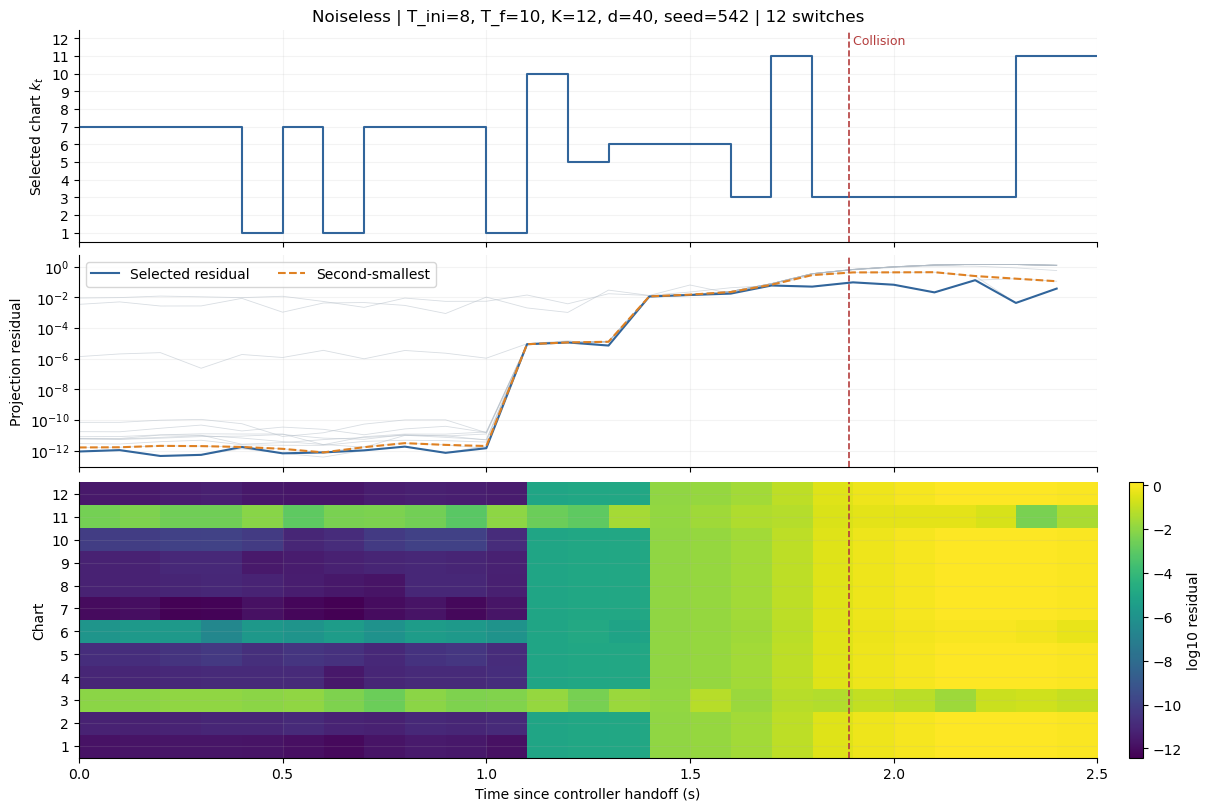

In [3]:
time = selection["time_s"]
charts = selection["chart_one_based"]
residuals = selection["residuals"]
chosen_residual = residuals[np.arange(len(time)), charts-1]
second_residual = np.sort(residuals, axis=1)[:, min(1, K-1)]
end_time = max(report["protocol"]["dt"], len(time)*report["protocol"]["dt"])
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True,
                         gridspec_kw={"height_ratios": [1, 1, 1.3]}, constrained_layout=True)
axes[0].step(np.r_[time, end_time], np.r_[charts, charts[-1]], where="post", color="#31659b")
axes[0].set(ylabel="Selected chart $k_t$", yticks=np.arange(1,K+1), ylim=(.5,K+.5))
axes[0].set_title(f"Noiseless | T_ini={T_INI}, T_f={T_F}, K={K}, d={D}, seed={SEED} | "
                  f"{diagnostics['switches']} switches")
for k in range(K):
    axes[1].semilogy(time, np.maximum(residuals[:,k], 1e-16), color="#b2bcc6", alpha=.5, lw=.6)
axes[1].semilogy(time, np.maximum(chosen_residual, 1e-16), color="#31659b", label="Selected residual")
axes[1].semilogy(time, np.maximum(second_residual, 1e-16), color="#df8123", ls="--", label="Second-smallest")
axes[1].set_ylabel("Projection residual")
axes[1].legend(ncol=2)
mesh = axes[2].imshow(np.log10(np.maximum(residuals.T, 1e-16)), origin="lower", aspect="auto",
                     extent=(0,end_time,.5,K+.5), cmap="viridis", interpolation="nearest")
axes[2].set(xlabel="Time since controller handoff (s)", ylabel="Chart", yticks=np.arange(1,K+1))
fig.colorbar(mesh, ax=axes[2], label="log10 residual", pad=.02)
for ax in axes:
    ax.set_xlim(0,end_time)
    ax.grid(alpha=.15)
    ax.spines[["top","right"]].set_visible(False)
hit = diagnostics["collision_replay"].get("collision_control_and_substep")
if hit is not None:
    collision_time = hit[0]*report["protocol"]["dt"]+(hit[1]+1)*.01
    for ax in axes:
        ax.axvline(collision_time, color="#b43d3d", ls="--", lw=1.2)
    axes[0].text(collision_time, K+.25, " Collision", color="#b43d3d", fontsize=9,
                 ha="left", va="top")
FIGURE_PATH = RESULT_DIR / "chart_selection_over_time.png"
fig.savefig(FIGURE_PATH, dpi=180)
fig.savefig(RESULT_DIR / "chart_selection_over_time.pdf")
plt.show()

In [4]:
# Every chart switch: time and labels use the same convention as the figure.
changes = np.flatnonzero(np.diff(charts)) + 1
switch_table = pd.DataFrame({"control step": changes, "time (s)": time[changes],
                             "from chart": charts[changes-1], "to chart": charts[changes]})
print(f"Starts in chart {charts[0]}; {len(changes)} switches; "
      f"visited charts: {sorted(set(charts.tolist()))}")
with pd.option_context("display.max_rows", None):
    display(switch_table)
# Save all decisions, not only the transitions, for direct downstream use.
records = [{"step": int(t), "time_s": float(time[t]), "chart_one_based": int(charts[t]),
            "selected_residual": float(chosen_residual[t]), "tie_count": int(selection["tie_count"][t])}
           for t in range(len(time))]
(RESULT_DIR / "chart_selection_over_time.json").write_text(json.dumps(records, indent=2)+"\n")


Starts in chart 7; 12 switches; visited charts: [1, 3, 5, 6, 7, 10, 11]


,control step,time (s),from chart,to chart
0,4,0.4,7,1
1,5,0.5,1,7
2,6,0.6,7,1
3,7,0.7,1,7
4,10,1.0,7,1
5,11,1.1,1,10
6,12,1.2,10,5
7,13,1.3,5,6
8,16,1.6,6,3
9,17,1.7,3,11


3543

## Historical tuned collision-free case (commanded inputs)

**K=13, d=44**, with the same **T_ini=8, T_f=10, σ=0, seed 542**, completes a
collision-free lap: **7.67 cm cross-track RMSE**, **223 steps (22.3 s)**,
**8 visited charts**, and **109 chart switches**. There are no failed QP solves.

Only K and d changed. The search considered ranks below the effective history
dimension (45) and stopped at its first collision-free case that visited multiple
charts. It evaluated 13 feasible configurations, all at the first rank tried,
d=44; settings without enough members in every chart were skipped. The results
below include all evaluated failures. Successful geometric laps were checked by
the simulator at every 0.01 s substep, including initialization.

**Selection caveat:** 17.0% of decisions have numerical ties, and the median
selected residual is only 3.43e-12. Switching is observed, but many decisions remain
sensitive to tiny residual differences. This is one tuned seed, not a multi-seed
robustness result, and is not evidence that chart switching itself improves control.

The full standalone trial was rerun with independent least-squares projection
checks, history reconstruction, noise checks, and collision replay. It reproduced
the search trajectory and chart sequence.

The third plot shows the saved **signed cross-track error in centimeters**
relative to the official raceline, on the same controller-time axis.

The shaded error band is ± the full-lap RMSE about zero (±7.67 cm); it is a
reference band for this trajectory, not a confidence interval.


In [5]:
SEARCH_DIR = ROOT / "experiments/f1tenth/history_projection_search/ti8_tf10_sigma0_seed542_39cc53ce3df4"
search_rows = json.loads((SEARCH_DIR / "search_ledger.json").read_text())
display(pd.DataFrame(search_rows)[["K", "d", "steps", "geometric_lap", "verified_success",
                                  "rmse_cm", "charts_visited", "switches", "tie_fraction"]]
        .rename(columns={"verified_success": "collision-free full lap", "rmse_cm": "RMSE (cm; recorded trajectory)"}))
print("RMSE values for failed trials are prefix metrics, not full-lap comparisons.")

,K,d,steps,geometric_lap,collision-free full lap,RMSE (cm; recorded trajectory),charts_visited,switches,tie_fraction
0,12,44,202,False,False,17.852540,8,106,0.173267
1,8,44,222,True,False,8.143613,6,91,0.207207
2,5,44,42,False,False,40.747737,5,30,0.047619
3,3,44,34,False,False,35.604533,3,9,0.000000
4,2,44,28,False,False,26.468894,2,1,0.000000
5,10,44,39,False,False,14.692998,4,10,0.307692
6,6,44,25,False,False,24.787491,5,7,0.120000
7,4,44,22,False,False,33.660365,3,8,0.090909
8,14,44,227,True,False,20.543541,9,131,0.057269
9,7,44,184,False,False,14.229571,7,58,0.048913


RMSE values for failed trials are prefix metrics, not full-lap comparisons.


In [6]:
%matplotlib inline
from pathlib import Path
import json
import os
import subprocess
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(root for parent in (Path.cwd(), *Path.cwd().parents)
            for root in (parent, parent / "code")
            if (root / "src/atlas_deepc").is_dir())
T_INI, T_F = 8, 10
K, D, SEED = 13, 44, 542
MAX_STEPS = 600
OUTPUT_ROOT = ROOT / "experiments/f1tenth/history_projection_trials"

RESULT_DIR = OUTPUT_ROOT / "ti8_tf10_k13_d44_sigma0_seed542_2ffb750ed9ec"
# Historical commanded-input result; display only.
report = json.loads((RESULT_DIR / "report.json").read_text())
summary, diagnostics = report["summary"], report["diagnostics"]
with np.load(RESULT_DIR / "selection_over_time.npz") as saved:
    selection = {k: saved[k].copy() for k in saved.files}
with np.load(RESULT_DIR / "rollout/rollout.npz") as saved:
    trajectory = {k: saved[k].copy() for k in saved.files}
print(f"Results: {RESULT_DIR}")

Results: /Users/kumiko/Projects/atlas_deepc/code/experiments/f1tenth/history_projection_trials/ti8_tf10_k13_d44_sigma0_seed542_2ffb750ed9ec


In [7]:
display(pd.DataFrame([{
    "T_ini": T_INI, "T_f": T_F, "K": K, "d": D, "seed": SEED,
    "measurement sigma": 0, "collision-free full lap": summary["verified_success"],
    "geometric full lap": summary["lap_completed"], "termination": summary["termination"],
    "applied steps": summary["steps"], "lap fraction": summary["lap_fraction"],
    "cross-track RMSE (cm; recorded prefix)": summary["rmse_cm"],
    "chart switches": diagnostics["switches"], "tie fraction": diagnostics["tie_fraction"],
}]).T.rename(columns={0:"Value"}))
print("H shape:", diagnostics["H_shape"], "| basis shape:", diagnostics["basis_shape"])
print("Selected residual min / median / max:",
      diagnostics["selected_residual_min"], diagnostics["selected_residual_median"],
      diagnostics["selected_residual_max"])
print("Validation:", diagnostics["validation"])
display(pd.DataFrame({
    "chart (1-based)": np.arange(1, K+1),
    "offline members": diagnostics["member_counts"],
    "history-subspace rank": diagnostics["past_ranks"],
    "selection count": diagnostics["chart_counts"],
}))

,Value
T_ini,8
T_f,10
K,13
d,44
seed,542
measurement sigma,0
collision-free full lap,True
geometric full lap,True
termination,lap_completed
applied steps,223


H shape: [108, 2640] | basis shape: [13, 108, 44]
Selected residual min / median / max: 6.184731075587262e-14 3.43099844292619e-12 0.0018999622085545122
Validation: Independent least-squares residual, argmin/tie rule, observed-window reconstruction, and noiseless observations checked.


,chart (1-based),offline members,history-subspace rank,selection count
0,1,249,38,46
1,2,210,38,1
2,3,71,38,0
3,4,290,38,14
4,5,206,44,12
5,6,135,38,0
6,7,268,38,2
7,8,250,44,135
8,9,336,38,9
9,10,56,38,0


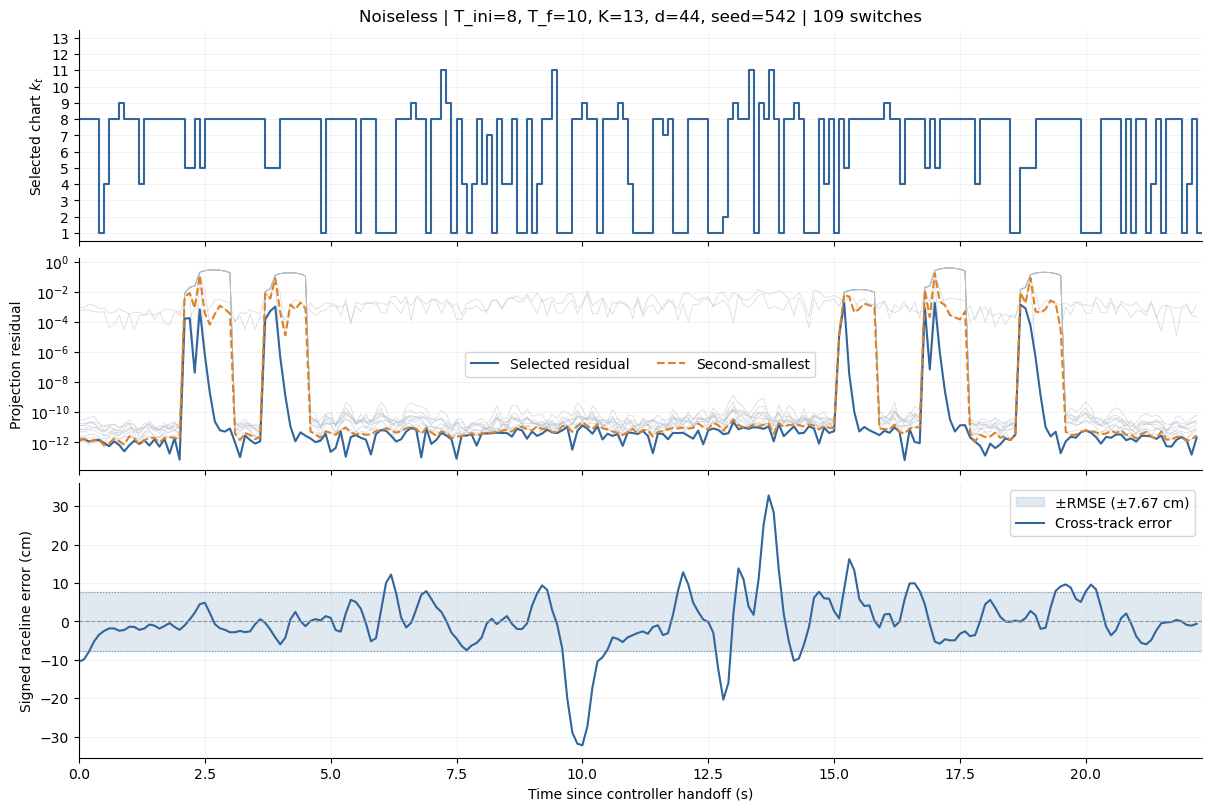

In [8]:
time = selection["time_s"]
charts = selection["chart_one_based"]
residuals = selection["residuals"]
chosen_residual = residuals[np.arange(len(time)), charts-1]
second_residual = np.sort(residuals, axis=1)[:, min(1, K-1)]
end_time = max(report["protocol"]["dt"], len(time)*report["protocol"]["dt"])
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True,
                         gridspec_kw={"height_ratios": [1, 1, 1.3]}, constrained_layout=True)
axes[0].step(np.r_[time, end_time], np.r_[charts, charts[-1]], where="post", color="#31659b")
axes[0].set(ylabel="Selected chart $k_t$", yticks=np.arange(1,K+1), ylim=(.5,K+.5))
axes[0].set_title(f"Noiseless | T_ini={T_INI}, T_f={T_F}, K={K}, d={D}, seed={SEED} | "
                  f"{diagnostics['switches']} switches")
for k in range(K):
    axes[1].semilogy(time, np.maximum(residuals[:,k], 1e-16), color="#b2bcc6", alpha=.5, lw=.6)
axes[1].semilogy(time, np.maximum(chosen_residual, 1e-16), color="#31659b", label="Selected residual")
axes[1].semilogy(time, np.maximum(second_residual, 1e-16), color="#df8123", ls="--", label="Second-smallest")
axes[1].set_ylabel("Projection residual")
axes[1].legend(ncol=2)
# Saved signed cross-track error relative to the official raceline.
tracking_error_cm = 100 * np.asarray(trajectory["cross_track_error"])
tracking_time = np.arange(len(tracking_error_cm)) * report["protocol"]["dt"]
np.testing.assert_allclose(np.sqrt(np.mean(tracking_error_cm**2)), summary["rmse_cm"])
rmse_cm = float(np.sqrt(np.mean(tracking_error_cm**2)))
axes[2].axhspan(-rmse_cm, rmse_cm, color="#31659b", alpha=.14, zorder=0,
                label=f"±RMSE (±{rmse_cm:.2f} cm)")
axes[2].axhline(rmse_cm, color="#31659b", lw=.8, ls=":", alpha=.6)
axes[2].axhline(-rmse_cm, color="#31659b", lw=.8, ls=":", alpha=.6)
axes[2].plot(tracking_time, tracking_error_cm, color="#31659b", lw=1.5,
             label="Cross-track error")
axes[2].axhline(0, color="#8c969f", lw=.8, ls="--")
axes[2].set(xlabel="Time since controller handoff (s)", ylabel="Signed raceline error (cm)")
axes[2].legend(loc="upper right")
for ax in axes:
    ax.set_xlim(0,end_time)
    ax.grid(alpha=.15)
    ax.spines[["top","right"]].set_visible(False)
hit = diagnostics["collision_replay"].get("collision_control_and_substep")
if hit is not None:
    collision_time = hit[0]*report["protocol"]["dt"]+(hit[1]+1)*.01
    for ax in axes:
        ax.axvline(collision_time, color="#b43d3d", ls="--", lw=1.2)
    axes[0].text(collision_time, K+.25, " Collision", color="#b43d3d", fontsize=9,
                 ha="left", va="top")
FIGURE_PATH = RESULT_DIR / "chart_selection_over_time.png"
fig.savefig(FIGURE_PATH, dpi=180)
fig.savefig(RESULT_DIR / "chart_selection_over_time.pdf")
plt.show()

In [9]:
# Every chart switch: time and labels use the same convention as the figure.
changes = np.flatnonzero(np.diff(charts)) + 1
switch_table = pd.DataFrame({"control step": changes, "time (s)": time[changes],
                             "from chart": charts[changes-1], "to chart": charts[changes]})
print(f"Starts in chart {charts[0]}; {len(changes)} switches; "
      f"visited charts: {sorted(set(charts.tolist()))}")
with pd.option_context("display.max_rows", None):
    display(switch_table)
# Save all decisions, not only the transitions, for direct downstream use.
records = [{"step": int(t), "time_s": float(time[t]), "chart_one_based": int(charts[t]),
            "selected_residual": float(chosen_residual[t]), "tie_count": int(selection["tie_count"][t])}
           for t in range(len(time))]
(RESULT_DIR / "chart_selection_over_time.json").write_text(json.dumps(records, indent=2)+"\n")


Starts in chart 8; 109 switches; visited charts: [1, 2, 4, 5, 7, 8, 9, 11]


,control step,time (s),from chart,to chart
0,4,0.4,8,1
1,5,0.5,1,4
2,6,0.6,4,8
3,8,0.8,8,9
4,9,0.9,9,8
5,12,1.2,8,4
6,13,1.3,4,8
7,21,2.1,8,5
8,23,2.3,5,8
9,24,2.4,8,5


31983

## Applied-input correction

The same K=13, d=44, T_ini=8, T_f=10, noiseless seed-542 trial now feeds
**applied** input histories to the controller. The acceleration entry is the
RK4-weighted acceleration averaged over the ten internal integration steps; it is
computed from simulator actuator telemetry, not noisy speed differences. Steering
is the actual held angle. Both the offline library and online history use this
convention. Commands remain separately recorded and are used for exact replay.
Averaging gives the correct longitudinal increment, but does not claim equivalence
to holding a constant average input for every nonlinear state equation.

The original 3,000 offline states/outputs are preserved, while replay corrects
80 acceleration entries. Clustering and SVD are rebuilt from the corrected
input/output columns. The simulator, QP, reference, weights, limits, and selection
rule are unchanged.

**Observed outcome:** the corrected run fails after 42 steps (4.2 s), with a
collision at 3.99 s and 12.78 cm RMSE over the failed prefix. All 13 restricted
chart bases have rank 38. Selected residuals remain between approximately
8.5e-13 and 2.1e-11, including intervals with acceleration limiting. Thus the old
spikes were caused by the input mismatch, but this correction does not solve the
subspace discrimination problem. With the seven exact speed-increment relations,
the effective noiseless history space is 48 - 3 - 7 = 38 dimensional.

The ±RMSE band here describes only the recorded failed prefix. The historical
paper table has not been rerun under the corrected convention.

In [10]:
%matplotlib inline
from pathlib import Path
import json
import os
import subprocess
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(root for parent in (Path.cwd(), *Path.cwd().parents)
            for root in (parent, parent / "code")
            if (root / "src/atlas_deepc").is_dir())
T_INI, T_F = 8, 10
K, D, SEED = 13, 44, 542
MAX_STEPS = 600
OUTPUT_ROOT = ROOT / "experiments/f1tenth/history_projection_trials"

env = os.environ.copy()
env.update(OPENBLAS_NUM_THREADS="1", OMP_NUM_THREADS="1", MKL_NUM_THREADS="1")
command = [sys.executable, str(ROOT / "scripts/run_f1tenth_history_trial.py"),
           "--t-ini", str(T_INI), "--t-f", str(T_F), "--clusters", str(K),
           "--rank", str(D), "--seed", str(SEED), "--steps", str(MAX_STEPS),
           "--output-root", str(OUTPUT_ROOT)]
completed = subprocess.run(command, cwd=ROOT, env=env, text=True, capture_output=True)
if completed.returncode:
    print(completed.stdout)
    print(completed.stderr)
    completed.check_returncode()
RESULT_DIR = Path(next(line.split("=", 1)[1] for line in completed.stdout.splitlines()
                       if line.startswith("RESULT_DIRECTORY=")))
report = json.loads((RESULT_DIR / "report.json").read_text())
summary, diagnostics = report["summary"], report["diagnostics"]
with np.load(RESULT_DIR / "selection_over_time.npz") as saved:
    selection = {k: saved[k].copy() for k in saved.files}
with np.load(RESULT_DIR / "rollout/rollout.npz") as saved:
    trajectory = {k: saved[k].copy() for k in saved.files}
print(f"Results: {RESULT_DIR}")

Results: /Users/kumiko/Projects/atlas_deepc/code/experiments/f1tenth/history_projection_trials/ti8_tf10_k13_d44_sigma0_seed542_d569e6ba8811


In [11]:
display(pd.DataFrame([{
    "T_ini": T_INI, "T_f": T_F, "K": K, "d": D, "seed": SEED,
    "measurement sigma": 0, "collision-free full lap": summary["verified_success"],
    "geometric full lap": summary["lap_completed"], "termination": summary["termination"],
    "applied steps": summary["steps"], "lap fraction": summary["lap_fraction"],
    "cross-track RMSE (cm; recorded prefix)": summary["rmse_cm"],
    "chart switches": diagnostics["switches"], "tie fraction": diagnostics["tie_fraction"],
}]).T.rename(columns={0:"Value"}))
print("H shape:", diagnostics["H_shape"], "| basis shape:", diagnostics["basis_shape"])
print("Selected residual min / median / max:",
      diagnostics["selected_residual_min"], diagnostics["selected_residual_median"],
      diagnostics["selected_residual_max"])
print("Validation:", diagnostics["validation"])
display(pd.DataFrame({
    "chart (1-based)": np.arange(1, K+1),
    "offline members": diagnostics["member_counts"],
    "history-subspace rank": diagnostics["past_ranks"],
    "selection count": diagnostics["chart_counts"],
}))

,Value
T_ini,8
T_f,10
K,13
d,44
seed,542
measurement sigma,0
collision-free full lap,False
geometric full lap,False
termination,track_corridor_exit
applied steps,42


H shape: [108, 2640] | basis shape: [13, 108, 44]
Selected residual min / median / max: 8.485864253762398e-13 2.875956355714567e-12 2.0532750431499213e-11
Validation: Applied input history/replay, independent least-squares residual, argmin/tie rule, observed-window reconstruction, and noiseless observations checked.


,chart (1-based),offline members,history-subspace rank,selection count
0,1,249,38,18
1,2,210,38,1
2,3,71,38,0
3,4,290,38,1
4,5,206,38,7
5,6,135,38,0
6,7,268,38,0
7,8,250,38,2
8,9,336,38,5
9,10,56,38,0


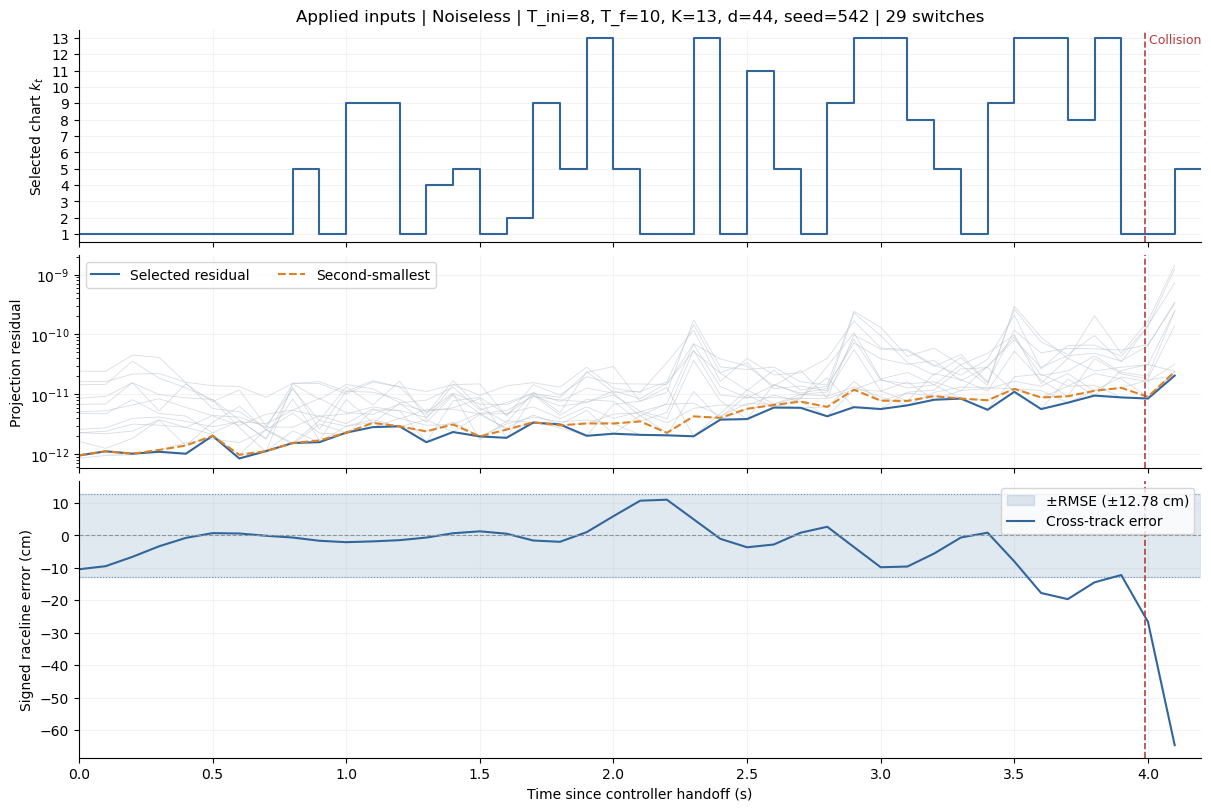

In [12]:
time = selection["time_s"]
charts = selection["chart_one_based"]
residuals = selection["residuals"]
chosen_residual = residuals[np.arange(len(time)), charts-1]
second_residual = np.sort(residuals, axis=1)[:, min(1, K-1)]
end_time = max(report["protocol"]["dt"], len(time)*report["protocol"]["dt"])
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True,
                         gridspec_kw={"height_ratios": [1, 1, 1.3]}, constrained_layout=True)
axes[0].step(np.r_[time, end_time], np.r_[charts, charts[-1]], where="post", color="#31659b")
axes[0].set(ylabel="Selected chart $k_t$", yticks=np.arange(1,K+1), ylim=(.5,K+.5))
axes[0].set_title(f"Applied inputs | Noiseless | T_ini={T_INI}, T_f={T_F}, K={K}, d={D}, seed={SEED} | "
                  f"{diagnostics['switches']} switches")
for k in range(K):
    axes[1].semilogy(time, np.maximum(residuals[:,k], 1e-16), color="#b2bcc6", alpha=.5, lw=.6)
axes[1].semilogy(time, np.maximum(chosen_residual, 1e-16), color="#31659b", label="Selected residual")
axes[1].semilogy(time, np.maximum(second_residual, 1e-16), color="#df8123", ls="--", label="Second-smallest")
axes[1].set_ylabel("Projection residual")
axes[1].legend(ncol=2)
# Saved signed cross-track error relative to the official raceline.
tracking_error_cm = 100 * np.asarray(trajectory["cross_track_error"])
tracking_time = np.arange(len(tracking_error_cm)) * report["protocol"]["dt"]
np.testing.assert_allclose(np.sqrt(np.mean(tracking_error_cm**2)), summary["rmse_cm"])
rmse_cm = float(np.sqrt(np.mean(tracking_error_cm**2)))
axes[2].axhspan(-rmse_cm, rmse_cm, color="#31659b", alpha=.14, zorder=0,
                label=f"±RMSE (±{rmse_cm:.2f} cm)")
axes[2].axhline(rmse_cm, color="#31659b", lw=.8, ls=":", alpha=.6)
axes[2].axhline(-rmse_cm, color="#31659b", lw=.8, ls=":", alpha=.6)
axes[2].plot(tracking_time, tracking_error_cm, color="#31659b", lw=1.5,
             label="Cross-track error")
axes[2].axhline(0, color="#8c969f", lw=.8, ls="--")
axes[2].set(xlabel="Time since controller handoff (s)", ylabel="Signed raceline error (cm)")
axes[2].legend(loc="upper right")
for ax in axes:
    ax.set_xlim(0,end_time)
    ax.grid(alpha=.15)
    ax.spines[["top","right"]].set_visible(False)
hit = diagnostics["collision_replay"].get("collision_control_and_substep")
if hit is not None:
    collision_time = hit[0]*report["protocol"]["dt"]+(hit[1]+1)*.01
    for ax in axes:
        ax.axvline(collision_time, color="#b43d3d", ls="--", lw=1.2)
    axes[0].text(collision_time, K+.25, " Collision", color="#b43d3d", fontsize=9,
                 ha="left", va="top")
FIGURE_PATH = RESULT_DIR / "chart_selection_over_time.png"
fig.savefig(FIGURE_PATH, dpi=180)
fig.savefig(RESULT_DIR / "chart_selection_over_time.pdf")
plt.show()

In [13]:
# Applied input history and plant telemetry must agree, including warmup.
assert summary["input_history_convention"] == "applied_rk4_average_v1"
assert diagnostics["applied_input_validation"]["verified"]
np.testing.assert_array_equal(trajectory["input_history"][1:],
    np.vstack((trajectory["warmup_inputs"], trajectory["U"])))
limited = np.flatnonzero(np.abs(trajectory["U"][:,0]-trajectory["U_commanded"][:,0])>1e-10)
display(pd.DataFrame({"time (s)": limited * report["protocol"]["dt"],
                      "commanded acceleration (m/s²)": trajectory["U_commanded"][limited,0],
                      "applied average acceleration (m/s²)": trajectory["U"][limited,0]}))
print("Offline and online histories use applied inputs; collision replay uses commands.")

,time (s),commanded acceleration (m/s²),applied average acceleration (m/s²)
0,2.1,0.286513,0.281738
1,3.8,3.000000,0.688551
2,4.0,3.000000,2.797829
3,4.1,3.000000,0.137442


Offline and online histories use applied inputs; collision replay uses commands.


In [14]:
# Every chart switch: time and labels use the same convention as the figure.
changes = np.flatnonzero(np.diff(charts)) + 1
switch_table = pd.DataFrame({"control step": changes, "time (s)": time[changes],
                             "from chart": charts[changes-1], "to chart": charts[changes]})
print(f"Starts in chart {charts[0]}; {len(changes)} switches; "
      f"visited charts: {sorted(set(charts.tolist()))}")
with pd.option_context("display.max_rows", None):
    display(switch_table)
# Save all decisions, not only the transitions, for direct downstream use.
records = [{"step": int(t), "time_s": float(time[t]), "chart_one_based": int(charts[t]),
            "selected_residual": float(chosen_residual[t]), "tie_count": int(selection["tie_count"][t])}
           for t in range(len(time))]
(RESULT_DIR / "chart_selection_over_time.json").write_text(json.dumps(records, indent=2)+"\n")


Starts in chart 1; 29 switches; visited charts: [1, 2, 4, 5, 8, 9, 11, 13]


,control step,time (s),from chart,to chart
0,8,0.8,1,5
1,9,0.9,5,1
2,10,1.0,1,9
3,12,1.2,9,1
4,13,1.3,1,4
5,14,1.4,4,5
6,15,1.5,5,1
7,16,1.6,1,2
8,17,1.7,2,9
9,18,1.8,9,5


6006